Best solution: [0.5984739  0.44686275]
Objective value: 213.96025721039845


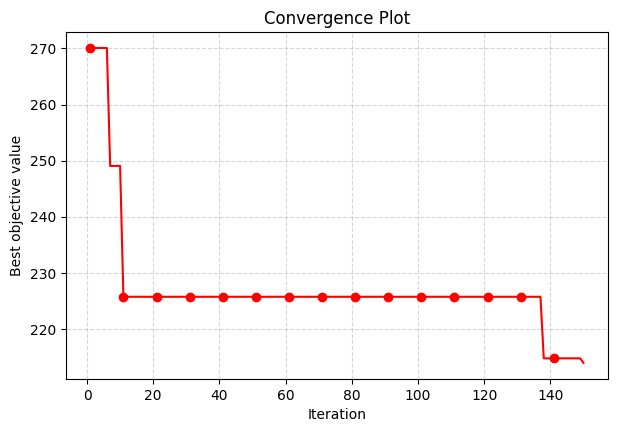

In [7]:
import numpy as np
import scipy.special as special
import matplotlib.pyplot as plt

BOUNDS = [(0.1, 5.0), (0.1, 5.0)]
L = 100.0
P = 2.0
SIGMA_MAX = 2.0

def objective_function(x):
    x1, x2 = x[0], x[1]
    volume = (2 * np.sqrt(2) * x1 + x2) * L
    stress_1 = (P * (np.sqrt(2) * x1 + x2)) / (2 * x1**2 + 2 * np.sqrt(2) * x1 * x2)
    stress_2 = P / (x1 + np.sqrt(2) * x2)
    penalty = 0.0
    if stress_1 > SIGMA_MAX:
        penalty += 1e6 * (stress_1 - SIGMA_MAX)**2
    if stress_2 > SIGMA_MAX:
        penalty += 1e6 * (stress_2 - SIGMA_MAX)**2
    return volume + penalty

def levy_flight(step_size=0.01, dim=2, beta=1.5):
    num = special.gamma(1 + beta) * np.sin(np.pi * beta / 2)
    den = special.gamma((1 + beta) / 2) * beta * (2**((beta - 1) / 2))
    sigma_u = (num / den)**(1 / beta)
    u = np.random.normal(0, sigma_u, dim)
    v = np.random.normal(0, 1, dim)
    step = u / (np.abs(v)**(1 / beta))
    return step_size * step

def cuckoo_search_structural(n_nests=25, p_a=0.25, max_iter=150):
    dim = len(BOUNDS)
    lb = np.array([b[0] for b in BOUNDS])
    ub = np.array([b[1] for b in BOUNDS])

    nests = lb + (ub - lb) * np.random.rand(n_nests, dim)
    fitness = np.array([objective_function(nest) for nest in nests])

    best_idx = np.argmin(fitness)
    best_nest = nests[best_idx].copy()
    best_fitness = fitness[best_idx]

    convergence_curve = []

    for iteration in range(max_iter):
        for i in range(n_nests):
            new_nest = nests[i] + levy_flight(dim=dim) * (nests[i] - best_nest)
            new_nest = np.clip(new_nest, lb, ub)
            new_fit = objective_function(new_nest)
            if new_fit < fitness[i]:
                nests[i] = new_nest
                fitness[i] = new_fit

        for i in range(n_nests):
            if np.random.rand() < p_a:
                r1, r2 = np.random.randint(0, n_nests, 2)
                nests[i] = nests[i] + np.random.rand() * (nests[r1] - nests[r2])
                nests[i] = np.clip(nests[i], lb, ub)
                fitness[i] = objective_function(nests[i])

        current_best_idx = np.argmin(fitness)
        if fitness[current_best_idx] < best_fitness:
            best_fitness = fitness[current_best_idx]
            best_nest = nests[current_best_idx].copy()

        convergence_curve.append(best_fitness)

    return best_nest, best_fitness, convergence_curve

best_dimensions, min_volume, history = cuckoo_search_structural()

print(f"Best solution: {best_dimensions}")
print(f"Objective value: {min_volume}")

plt.figure(figsize=(7, 4.5))
plt.plot(range(1, len(history) + 1), history, color='red', linestyle='-', marker='o', markevery=10)
plt.title('Convergence Plot')
plt.xlabel('Iteration')
plt.ylabel('Best objective value')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
